# IMDb Sentiment Analysis

[Open project.ipynb in Google Colab](https://colab.research.google.com/github/Noodleweb/IMDB-Sentiment-Anlysis---Group-2/blob/main/project.ipynb)

## Eploring the data

In [12]:
# Install dependencies as needed:
# pip install kagglehub
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

filepath = os.path.join(path, "IMDB Dataset.csv")

df_sentiments = pd.read_csv(filepath, encoding="latin1")

In [13]:
# Print some information about the dataset
print(df_sentiments.info())
df_sentiments.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened ...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometim...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted ...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />Thi...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. Thi...",positive


To get a better overview of the positive and negative sentiments, we can plot the distrubution of negative and positive to see if there is any imbalance.

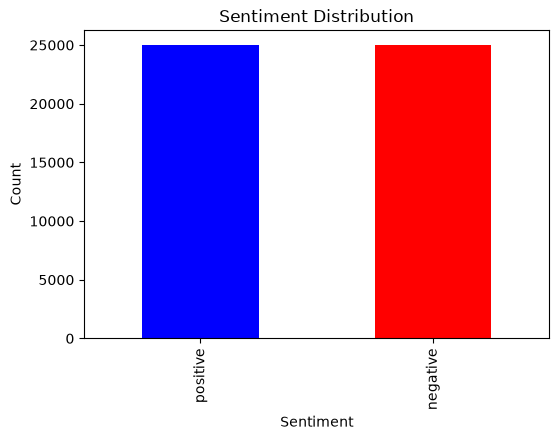

In [14]:
import matplotlib.pyplot as plt
sentiment_counts = df_sentiments['sentiment'].value_counts()

plt.figure(figsize=(6, 4))
sentiment_counts.plot(kind='bar', color=['blue', 'red'])

plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.title("Sentiment Distribution")
plt.show()

The negative and positive classes seem to be perfectly balanced, which makes things easier for us as we wont have to worry about class imbalance impacting our evaluation metrics. In the case that they were imbalanced, one could apply balancing techniques such as SMOTE or class weighting. We can now move on to inspecting the features.

We can start by printing out a slightly longer samples of the reviews and see if we can discover any irregularities. At a first look, we see some HTML line break "\<br />" that got included into our dataset as part of the review scraping process. These elements can be stripped away as they don't add any important information to our models.

In [15]:
pd.set_option('display.max_colwidth', 150)
sample = df_sentiments.iloc[0:20]
print(sample['review'])

0     One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened ...
1     A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometim...
2     I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted ...
3     Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />Thi...
4     Petter Mattei's "Love in the Time of Money" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. Thi...
5     Probably my all-time favorite movie, a story of selflessness, sacrifice and dedication to a noble cause, but it's not preachy or boring. It just n...
6     I sure would like to see a resurrection of a up dated Seah

Depending on the type of model we will be using, data preprocessing will have to be considered. We will begin by using simpler models such as Random forest and Naive Bayes together with a feature extraction technique such as *TF-IDF* which is a type of text vectorizer. These models predict sentiments based on keywords. In order to improve the performance we need to make the data more homogenous and structured.

## Data pre-processing

Some traditional models require a feature extraction method to be used before the data is being fed to the model. These methods include Bag of Words, TF-IDF and N-grams. In order for these techniques to work optimally, we have to clean the data beforehand so that the features don't include noise. Furthermore, it will reduce the dimensionality of our feature set by consolidating different variations of the same word.

There are different ways we can transform the data to make it better prepared for feature extraction. We will only focus on the most impactful transformations:

* Removing line breaks \<br />

* Lowercasing
    * In order to keep our vocabulary consistent, we combine different writings of the same words such as bad, BAD and Bad into a single feature (bad) so that it maps to the same value in our vectorizer.
* Contractions
    * Words like (don't, wasn't) will be expanded to (do not and was not). Similar to lowercasing, this is to ensure that the same words are consistenly grouped as the same feature.
* Special characters
    * Some characters may introduce unecessary noise in the dataset which can separate the the words into distinct groupings, for example (good) and good is treated as different because of the brackets.
    * We will slectively retain exclamation marks and question marks because they have significant weight in the sentiments.

In [16]:
import re

def preprocess_text(text):

    # Remove <br/> tags
    text = re.sub(r'<br\s*/?>', ' ', text)

    # lowercasing
    text = text.lower()

    # Expand some common contractions
    text = re.sub(r"\b(it|he|she|that|there|what|who)'s\b", r"\1 is", text) # specific 's contractions to avoid possesives
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "cannot", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'ve\b", " have", text)
    text = re.sub(r"'re\b", " are", text)
    text = re.sub(r"'ll\b", " will", text)
    text = re.sub(r"'m\b", " am", text)

    # Remove special characters and keep !,?,/
    text = re.sub(r"[^a-z0-9!?/\s]", "", text)

    # Remove the extra spacing
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df_sentiments['cleaned_review'] = df_sentiments['review'].apply(preprocess_text) # Creating a new column containing the cleaned data

10 rows are sampled from the raw and cleaned reviews and are printed side by side for comparison.

In [17]:
print("Raw reviews:")
sample = df_sentiments.iloc[55:65]
print(sample["review"])
print("\nCleaned reviews:")
print(sample['cleaned_review'])

Raw reviews:
55    As someone has already mentioned on this board, it's very difficult to make a fake documentary. It requires tremendous skill, pacing, patience, di...
56    The Hills Have Eyes II is what you would expect it to be and nothing more. Of course it's not going to be an Oscar nominated film, it's just pure ...
57    I laughed all the way through this rotten movie. It's so unbelievable. A woman leaves her husband after many years of marriage, has a breakdown in...
58    NO SPOILERS!!<br /><br />After Hitchcock's successful first American film, Rebecca based upon Daphne DuMarier's lush novel of gothic romance and i...
59    I just watched The Dresser this evening, having only seen it once before, about a dozen years ago.<br /><br />It's not a "big" movie, and doesn't ...
60    What happened? What we have here is basically a solid and plausible premise and with a decent and talented cast, but somewhere the movie loses it....
61    I've just watched Fingersmith, and I'm stunne

Looking at the final result of the pre-processing, we see that the line break elements are removed and all words are in lowercase. The text now follows a more uniform structure, which is easier for a vectorizer to extract its features.

## Testing Models

As a start we will begin testing the data on some traditional machine learning algorithm. Each model will be evaluated using default parameters to identify the most promising candidates. Given that the classes are balanced in this dataset, accuracy will be used to measure the performance of each classifier. To preprocess the raw text, we will use TF-IDF for feature extraction.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

Before training, we need to follow the guidelines from the people who designed this dataset. The first 25,000 rows in this dataset were specifically designated for training, while the other half of the dataset is used for testing. The researchers specifically partitioned the dataset in this way so that the movie reviews are completely disjoint, ensuring that no reviews for a specific movie leak between the train and test sets.

In [19]:
# Separate a hold-out test set to prevent data leakage
df_train = df_sentiments.iloc[0:25000].copy()
df_test = df_sentiments.iloc[25000:50000].copy()

X_train = df_train['cleaned_review']
y_train = df_train['sentiment']

X_test = df_test['cleaned_review']
y_test = df_test['sentiment']

The standard tf-idf tokenizer strips all special characters from the words. If we want to keep these features, we have to define our own tokenizer pattern.

In [20]:
vectorizer = TfidfVectorizer(
    strip_accents='unicode',
    token_pattern=r"(?u)\b\w+\b|[!?/]"  # Keep punctuation tokens like ! or ?
)

In [21]:
from sklearn.model_selection import cross_val_score
import numpy as np

def evaluate_baseline_classifier(classifier):
    # Create a pipeline that combines TF-IDF vectorization and the classifier
    model = make_pipeline(vectorizer, classifier)

    # run cross validation on the training set
    scores = cross_val_score(model, X_train, y_train, cv=4, n_jobs=-1)
    print(f"Mean CV Accuracy: {np.mean(scores):.4f}")

In [22]:
from sklearn.linear_model import LogisticRegression
evaluate_baseline_classifier(LogisticRegression())

Mean CV Accuracy: 0.8861


In [23]:
from sklearn.svm import LinearSVC
evaluate_baseline_classifier(LinearSVC(dual='auto'))

Mean CV Accuracy: 0.8917


In [24]:
from sklearn.tree import DecisionTreeClassifier
evaluate_baseline_classifier(DecisionTreeClassifier())

Mean CV Accuracy: 0.7048


In [25]:
from sklearn.ensemble import RandomForestClassifier
evaluate_baseline_classifier(RandomForestClassifier())

Mean CV Accuracy: 0.8377


In [26]:
from sklearn.naive_bayes import MultinomialNB
evaluate_baseline_classifier(MultinomialNB())

Mean CV Accuracy: 0.8563


Although these are only the preliminary metrics of our evalation, even simple linear such as logistic regression or SVC have an accuracy at around 90%. We will nominate 3 of the best contending classifiers from these tests and move on to hypeparameter tuning to see if we can achieve even better results with them.

### Hyperparemeter Tuning

For hyperparamter tuning we will use a RandomizedSearch to evaluate across different parameter combinations combinations. All models will be evaluated using cross validation agains 4 folds to ensure we are not lucky on a single train test validation split. We can pick even more folds but we decided that 4 is a good tradeoff between efficiency and a reliable estimate of performance. Besides tuning the hyperparameters of the classifier, you can also tune the hyperparameters of the vectorizer with parameters such as min_df or max_df which filters out overly common or overly rare words in the vocabulary.

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

In [35]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ('tfidf', vectorizer),
    ('clf', LogisticRegression(solver='liblinear',max_iter=1000))
])

params = {
    'clf__C': [ 0.1, 1, 10,100],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_df' : [0.5, 0.6, 0.7, 0.8],}

random_search_logistic = RandomizedSearchCV(logistic_pipeline, params, n_iter=16, cv=4, n_jobs=-1,random_state=42 ,verbose=1)
random_search_logistic.fit(X_train, y_train)

best_params_logistic = random_search_logistic.best_params_
best_score_logistic = random_search_logistic.best_score_

print(f"Best Parameters for Logistic Regression: {best_params_logistic}")
print(f"Best Accuracy for Logistic Regression: {best_score_logistic:.4f}")

best_model_logistic = random_search_logistic.best_estimator_ # Save the best model for later use

Fitting 4 folds for each of 16 candidates, totalling 64 fits
Best Parameters for Logistic Regression: {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 1, 'tfidf__max_df': 0.7, 'clf__C': 100}
Best Accuracy for Logistic Regression: 0.9076


In [36]:
from sklearn.svm import LinearSVC

svc_pipeline = Pipeline([
    ('tfidf', vectorizer),
    ('clf', LinearSVC(dual=False,max_iter=4000))
])

params = {
    'clf__C': [ 0.1, 1, 10,100],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_df' : [0.5, 0.6, 0.7, 0.8],
}

random_search_svc = RandomizedSearchCV(svc_pipeline, params, n_iter=16, cv=4, n_jobs=-1,random_state=42 ,verbose=1)
random_search_svc.fit(X_train, y_train)

best_params_svc = random_search_svc.best_params_
best_score_svc = random_search_svc.best_score_

print(f"Best Parameters for SVC: {best_params_svc}")
print(f"Best Accuracy for SVC: {best_score_svc:.4f}")

best_model_svc = random_search_svc.best_estimator_ # Save the best model for later use

Fitting 4 folds for each of 16 candidates, totalling 64 fits
Best Parameters for SVC: {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 1, 'tfidf__max_df': 0.7, 'clf__C': 10}
Best Accuracy for SVC: 0.9095


In [37]:
from sklearn.naive_bayes import MultinomialNB

nb_pipeline = Pipeline([
    ('tfidf', vectorizer),
    ('clf', MultinomialNB())
])

params = {
    'clf__alpha': [0.1, 0.5, 1.0],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_df': [0.5, 0.6, 0.7, 0.8]
}

random_search_nb = RandomizedSearchCV(nb_pipeline, params, n_iter=16, cv=4, n_jobs=-1, random_state=42, verbose=1)
random_search_nb.fit(X_train, y_train)

best_params_nb = random_search_nb.best_params_
best_score_nb = random_search_nb.best_score_

print(f"Best Parameters for Naive Bayes: {best_params_nb}")
print(f"Best Accuracy for Naive Bayes: {best_score_nb:.4f}")

best_model_nb = random_search_nb.best_estimator_ # Save the best model for later use

Fitting 4 folds for each of 16 candidates, totalling 64 fits
Best Parameters for Naive Bayes: {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 5, 'tfidf__max_df': 0.8, 'clf__alpha': 0.1}
Best Accuracy for Naive Bayes: 0.8854


Using randomized search we managed to refine our models slightly more in terms of accuracy by 1-2 percentage points with respect to the default parameter models. We may have achieved slightly better results if we increased the search space in our hyperparameters but going even further than 2% improvement, the linear models begin to reach their theoretical limits in accuracy for this dataset.

### Model Evaluation

In this section we will evaluate and interpret the classifiers tuned in the previus section to decide which model performs best across different metrics of evaluation using the holdout test set.

#### Feature Importances

Before looking at the metrics, we can take a look which features each model found to be most important when determining what sentiment of a movie. Feature importances can be actracted using the learned weights from the coef_ attribute for the LinearSVC and LogisticRegression models. Higher values or lower values correspond to stronger association to the negative or the positive class of the datset. Similarily, feature_log_prob_ exctracts the log propability of each feature for a corresponding class.

In [31]:
import numpy as np

def most_important_features(model, top_n=5):
    tfid_vectorizer = model.named_steps['tfidf']
    classifier = model.named_steps['clf']

    feature_names = tfid_vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0] #Extracting the weights

    # Sort indices from most negative to most positive
    sorted_indices = np.argsort(coefficients)

    # Negative features have the lowest coefficients
    top_negative_indices = sorted_indices[:top_n]
    
    # Positive features have the highest coefficients
    top_positive_indices = sorted_indices[-top_n:][::-1]

    top_negative_features = [(feature_names[i], coefficients[i]) for i in top_negative_indices]
    top_positive_features = [(feature_names[i], coefficients[i]) for i in top_positive_indices]

    print("Top Negative Features:")
    for feature, weight in top_negative_features:
        print(f"{feature}: {weight:.4f}")
    print("\nTop Positive Features:")
    for feature, weight in top_positive_features:
        print(f"{feature}: {weight:.4f}")

In [32]:
print("Top 10 most important features for Logistic Regression")
most_important_logistic = most_important_features(best_model_logistic)

Top 10 most important features for Logistic Regression
Top Negative Features:
bad: -14.2683
worst: -13.7813
awful: -12.6578
boring: -12.1236
the worst: -10.8842

Top Positive Features:
great: 12.3449
excellent: 10.4346
7: 8.1750
wonderful: 7.9854
perfect: 7.9261


In [33]:
print("\nTop 10 most important features for LinearSVC")
most_important_svc = most_important_features(best_model_svc)


Top 10 most important features for LinearSVC
Top Negative Features:
worst: -4.0079
awful: -3.9475
bad: -3.9022
boring: -3.6888
the worst: -3.1212

Top Positive Features:
great: 3.3700
excellent: 3.0295
7: 2.7193
8: 2.5094
wonderful: 2.3024


In [34]:
tfid_vectorizer = best_model_nb.named_steps['tfidf']
best_nb = best_model_nb.named_steps['clf']
feature_names = tfid_vectorizer.get_feature_names_out()

log_prob_neg = best_nb.feature_log_prob_[0]  # log probabilities for negative class
log_prob_pos = best_nb.feature_log_prob_[1]  # log probabilities for positive class
log_odds = log_prob_pos - log_prob_neg  # ratio of log probabilities

top_negative_indices = np.argsort(log_odds)[:5]  # Indices of top negative features
top_positive_indices = np.argsort(log_odds)[-5:]  # Indices of top positivLog-odds ratioe features

print("Top 5 Negative Features:")
for i in top_negative_indices:
    print(f"{feature_names[i]}: {log_odds[i]:.4f}")

print("\nTop 5 Positive Features:")
for i in top_positive_indices:
    print(f"{feature_names[i]}: {log_odds[i]:.4f}")


Top 5 Negative Features:
worst movies: -3.1900
waste of: -3.1605
worst movie: -3.1535
waste: -2.9427
waste your: -2.9286

Top 5 Positive Features:
wonderful film: 2.2670
8 /: 2.2738
a must: 2.2745
highly recommend: 2.3581
well worth: 2.5793


Looking at the highest ranked features, both LinearSVC and LogisticRegression have learned that the most important word for determining the sentiment of the positive classes is the word'great'. Naive Bayes was a bit different as it values bigrams such as 'worst movie' or 'wonderful film' higher more often than the other models that picked more unigrams.

#### Confusion Matrix

#### Precision/Recall curve

## Conclusion

The best performing model was...

#### Future work